In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from skimage.feature import hog
from skimage.io import imread

# Download the dataset and locate the image directory.
dataset_path = Path("../data")  # FER-2013 from Kaggle, shared at the repo root
image_dir = dataset_path / "train"
hog_output_dir = dataset_path / "hog_images"
hog_output_dir.mkdir(exist_ok=True)

features_by_image = []

# Walk through the emotion folders and process every image.
for image_path in sorted(image_dir.rglob("*")):
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    image = imread(image_path, as_gray=True)

    features, hog_image = hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True,
        block_norm="L2-Hys",
    )

    # Store the HOG vector and the original image class.
    features_by_image.append({
        "file": str(image_path),
        "class": image_path.parent.name,
        "features": features,
    })

    # Save the HOG visualization while preserving the class structure.
    output_path = hog_output_dir / image_path.relative_to(image_dir)
    output_path = output_path.with_suffix(".png")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.imsave(output_path, hog_image, cmap="gray")

print(f"Processed images: {len(features_by_image)}")
print(f"First HOG vector shape: {features_by_image[0]['features'].shape}")
print(f"HOG visualizations saved to: {hog_output_dir}")

Processed images: 28709
First HOG vector shape: (900,)
HOG visualizations saved to: ..\data\hog_images


In [2]:
from pathlib import Path

import joblib
import numpy as np
from skimage.feature import hog
from skimage.io import imread
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# Locate the dataset independently from the previous cell.
dataset_path = Path("../data")  # FER-2013 from Kaggle, shared at the repo root
image_dir = dataset_path / "train"

# Save model files in the repository's hog_svm directory.
project_dir = Path.cwd()
if project_dir.name == "hog_svm":
    project_dir = project_dir.parent

# Extract only the HOG vector; visualizations are not needed for SVM training.
def extract_hog(image_path):
    image = imread(image_path, as_gray=True)
    return hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=False,
        block_norm="L2-Hys",
    )

# Build the training data from the class folders.
X_train = []
y_train = []

for image_path in sorted(image_dir.rglob("*")):
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue
    X_train.append(extract_hog(image_path))
    y_train.append(image_path.parent.name)

X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train)

print(f"Training samples: {len(X_train)}")
print(f"HOG vector size: {X_train.shape[1]}")
print(f"Classes: {sorted(set(y_train))}")

# LinearSVC automatically trains one-vs-rest classifiers for the emotion classes.
svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(C=10.0, dual="auto", max_iter=5000, random_state=42),
)
svm_model.fit(X_train, y_train)

model_file = Path("hog_linear_svm.joblib")
joblib.dump(svm_model, model_file)
print(f"Model trained and saved to: {model_file}")

Training samples: 28709
HOG vector size: 900
Classes: [np.str_('angry'), np.str_('disgust'), np.str_('fear'), np.str_('happy'), np.str_('neutral'), np.str_('sad'), np.str_('surprise')]


Model trained and saved to: hog_linear_svm.joblib


Test samples: 7178
Test accuracy: 43.33%

Classification report:
              precision    recall  f1-score   support

       angry       0.35      0.26      0.30       958
     disgust       0.31      0.30      0.30       111
        fear       0.33      0.19      0.24      1024
       happy       0.52      0.77      0.62      1774
     neutral       0.38      0.41      0.40      1233
         sad       0.33      0.24      0.28      1247
    surprise       0.51      0.56      0.53       831

    accuracy                           0.43      7178
   macro avg       0.39      0.39      0.38      7178
weighted avg       0.41      0.43      0.41      7178



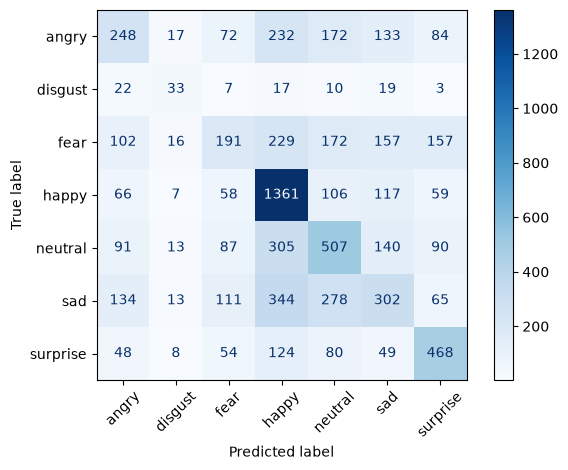

In [3]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
from skimage.feature import hog
from skimage.io import imread
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load the dataset, HOG extractor, and trained model independently.
dataset_path = Path("../data")  # FER-2013 from Kaggle, shared at the repo root
test_dir = dataset_path / "test"
project_dir = Path.cwd()
if project_dir.name == "hog_svm":
    project_dir = project_dir.parent
model_file = Path("hog_linear_svm.joblib")
svm_model = joblib.load(model_file)


def extract_hog(image_path):
    image = imread(image_path, as_gray=True)
    return hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=False,
        block_norm="L2-Hys",
    )

# Evaluate the trained HOG + SVM model on the official test split.
test_paths = sorted(
    image_path
    for image_path in test_dir.rglob("*")
    if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

X_test = []
y_test = []

for image_path in test_paths:
    X_test.append(extract_hog(image_path))
    y_test.append(image_path.parent.name)

X_test = np.asarray(X_test, dtype=np.float32)
y_test = np.asarray(y_test)

predictions = svm_model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print(f"Test samples: {len(X_test)}")
print(f"Test accuracy: {accuracy:.2%}")
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))

# Display the confusion matrix to see which emotions are confused most often.
labels = sorted(set(y_test) | set(predictions))
confusion = confusion_matrix(y_test, predictions, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=labels).plot(
    xticks_rotation=45,
    cmap="Blues",
)
plt.tight_layout()
plt.show()

Image: ..\data\test\angry\PrivateTest_10131363.jpg
True class: angry
Predicted class: sad
Confidence proxy: 21.11%
Latency: 4.03 ms


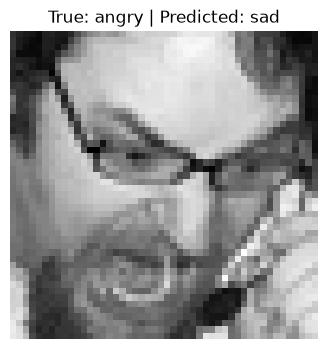

In [4]:
import time

# Test one image and report prediction, confidence, and latency.
sample_index = 0
sample_path = test_paths[sample_index]
sample_image = imread(sample_path, as_gray=True)

start_time = time.perf_counter()
sample_features = extract_hog(sample_path).reshape(1, -1)
sample_prediction = svm_model.predict(sample_features)[0]
sample_scores = svm_model.decision_function(sample_features).reshape(-1)
score_values = np.exp(sample_scores - sample_scores.max())
sample_confidence = float((score_values / score_values.sum()).max())
sample_latency = (time.perf_counter() - start_time) * 1000

print(f"Image: {sample_path}")
print(f"True class: {sample_path.parent.name}")
print(f"Predicted class: {sample_prediction}")
print(f"Confidence proxy: {sample_confidence:.2%}")
print(f"Latency: {sample_latency:.2f} ms")

plt.figure(figsize=(4, 4))
plt.imshow(sample_image, cmap="gray")
plt.title(f"True: {sample_path.parent.name} | Predicted: {sample_prediction}")
plt.axis("off")
plt.show()

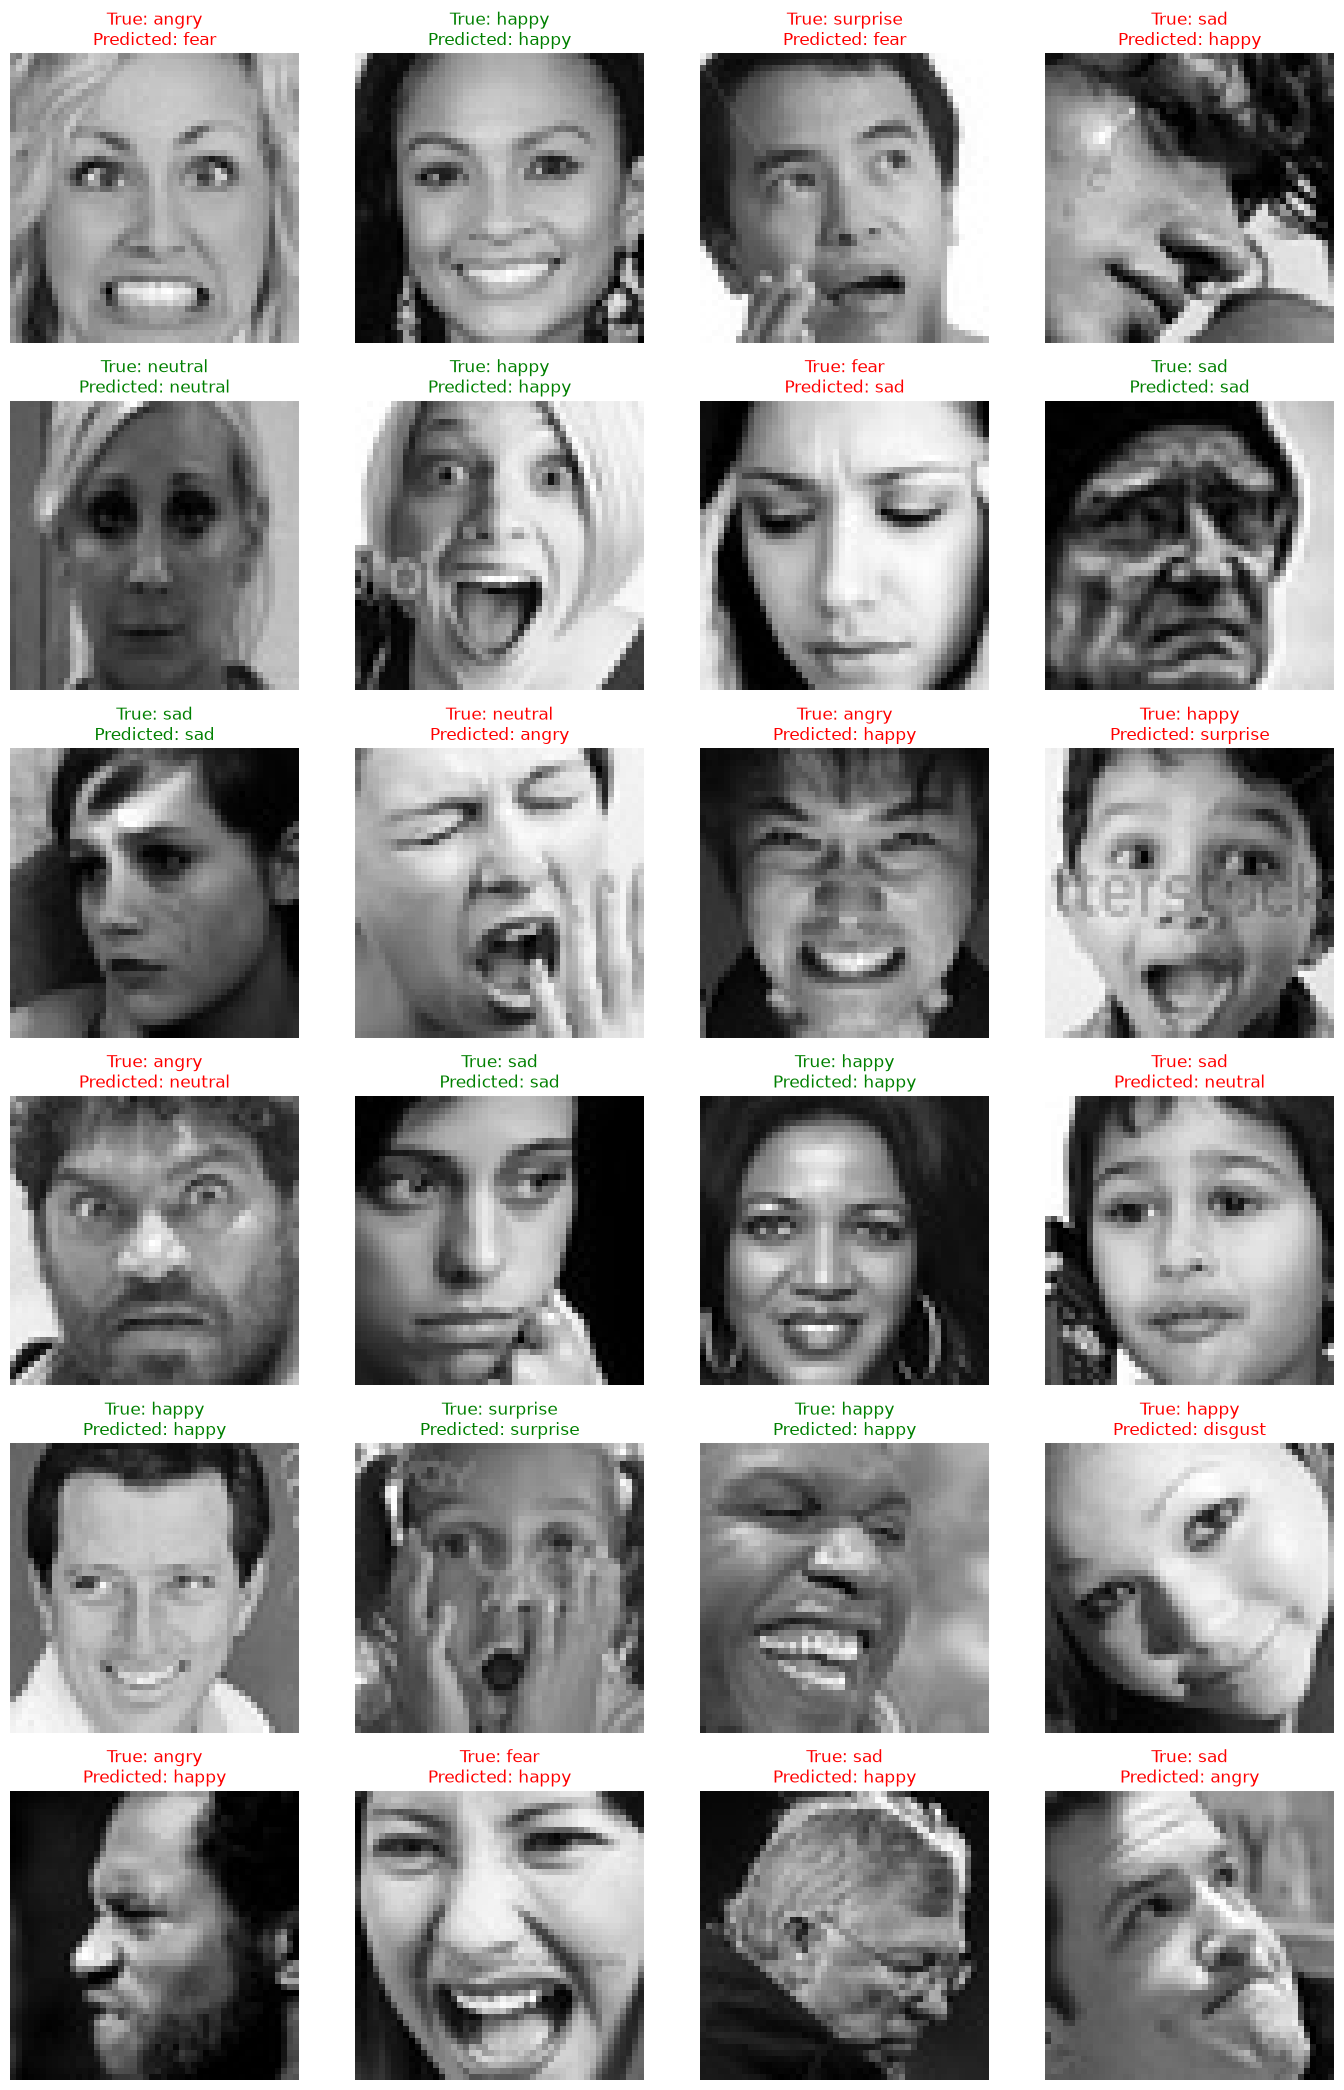

In [5]:
# Display several test images with their true and predicted classes.
number_of_images = 24
random_generator = np.random.default_rng(42)
selected_indices = random_generator.choice(
    len(test_paths),
    size=min(number_of_images, len(test_paths)),
    replace=False,
)

columns = 4
rows = int(np.ceil(len(selected_indices) / columns))
plt.figure(figsize=(14, 3.5 * rows))

for plot_index, image_index in enumerate(selected_indices, start=1):
    image = imread(test_paths[image_index], as_gray=True)
    true_class = y_test[image_index]
    predicted_class = predictions[image_index]
    title_color = "green" if true_class == predicted_class else "red"

    axis = plt.subplot(rows, columns, plot_index)
    axis.imshow(image, cmap="gray")
    axis.set_title(
        f"True: {true_class}\nPredicted: {predicted_class}",
        color=title_color,
    )
    axis.axis("off")

plt.tight_layout()
plt.show()